# Tech Challenge — Fase 1 · EXTRA
## Visão Computacional: diagnóstico por imagem com CNN

**Classificação de ultrassons de mama (maligno vs. não-maligno) com Rede Neural Convolucional**

---

Este notebook é o **item EXTRA** do desafio: além do modelo com dados
estruturados (câncer de mama Wisconsin), aqui aplicamos **Deep Learning /
Visão Computacional** diretamente sobre **imagens de exame**.

### Base de dados: BreastMNIST

- Derivada do **BUSI (Breast Ultrasound Images)** — 780 imagens de **ultrassom
  de mama** em tons de cinza.
- Disponibilizada pelo pacote **`medmnist`**, que baixa os dados automaticamente
  do Zenodo (**sem necessidade de Kaggle**), mantendo o projeto reprodutível.
- Tarefa: **classificação binária**. Convenção clínica do projeto:
  **`1 = maligno`** (classe positiva de interesse) e `0 = não-maligno`.
  *No dado cru o rótulo é `0 = maligno`, então remapeamos — assim recall volta
  a significar "proporção de malignos detectados".*

### Por que é um problema mais difícil que o tabular
O modelo tabular parte de **medições já extraídas** por especialistas. Aqui a
CNN precisa **aprender sozinha** os padrões visuais (formato do nódulo, bordas,
textura, sombra acústica) a partir de pixels — com um dataset pequeno e imagens
de baixa resolução. É esperado um desempenho mais modesto.


## 1. Setup

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import torch
import matplotlib.pyplot as plt

from src import config, vision

vision.set_seed(config.RANDOM_STATE)   # reprodutibilidade
print("PyTorch:", torch.__version__, "| threads:", torch.get_num_threads())
print("Classe positiva (recall):", vision.CLASS_NAMES[vision.POSITIVE_IS_MALIGNANT])


PyTorch: 2.12.1+cpu | threads: 14
Classe positiva (recall): maligno


## 2. Carregamento do BreastMNIST

Baixamos as imagens (64×64), montamos os `DataLoaders` do PyTorch e calculamos
os **pesos de classe** para compensar o desbalanceamento (o maligno é a
minoria) — os pesos entram na função de perda.

In [2]:
data = vision.load_breastmnist(image_size=64, batch_size=32)
counts = np.bincount(data.train_labels, minlength=2)
print(f"Treino: {counts.sum()} imagens | não-maligno: {counts[0]} | maligno: {counts[1]}")
print(f"Pesos de classe (perda): não-maligno={data.class_weights[0]:.2f}, maligno={data.class_weights[1]:.2f}")


Treino: 546 imagens | não-maligno: 399 | maligno: 147
Pesos de classe (perda): não-maligno=0.76, maligno=1.24


### 2.1 Como são as imagens

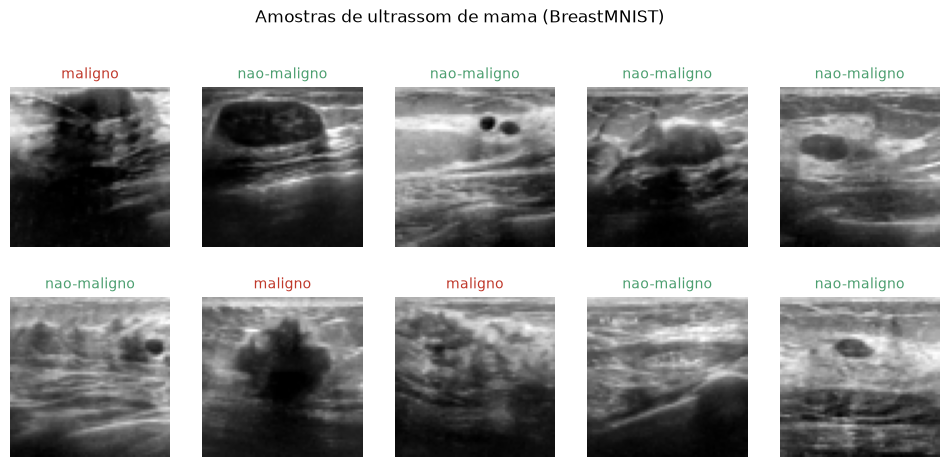

In [3]:
images, targets = next(iter(data.test_loader))
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(vision._denormalize(images[i]), cmap="gray")
    real = int(targets[i].view(-1)[0])
    ax.set_title(vision.CLASS_NAMES[real], fontsize=10,
                 color="#c0392b" if real == 1 else "#4c9f70")
    ax.axis("off")
fig.suptitle("Amostras de ultrassom de mama (BreastMNIST)", y=1.02)
plt.show()


**Observação:** são imagens pequenas, ruidosas e com baixo contraste —
típico de ultrassom. A olho nu, distinguir maligno de benigno exige experiência;
é justamente onde um apoio de IA pode ajudar (sem substituir o profissional).

## 3. Arquitetura da CNN

Uma CNN compacta com **três blocos convolucionais**
(`Conv → BatchNorm → ReLU → MaxPool`), que aprendem padrões locais cada vez mais
abstratos, seguidos de um classificador denso. `AdaptiveAvgPool` deixa a rede
robusta ao tamanho da imagem. É leve (~24 mil parâmetros), treina em CPU em
minutos, mas tem capacidade suficiente para o problema.

In [4]:
model = vision.BreastCNN()
n_params = sum(p.numel() for p in model.parameters())
print(f"Parâmetros treináveis: {n_params:,}\n")
print(model)


Parâmetros treináveis: 23,650

BreastCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool2d(output_size

## 4. Treinamento

Treinamos com **perda ponderada** (`CrossEntropyLoss` com pesos de classe) e
otimizador Adam. A cada época avaliamos na validação e **guardamos o melhor
checkpoint por F1** (uma forma de early-stopping). O treino é determinístico
(semente fixa), então os números são reprodutíveis.

Melhor F1 de validação: 0.760


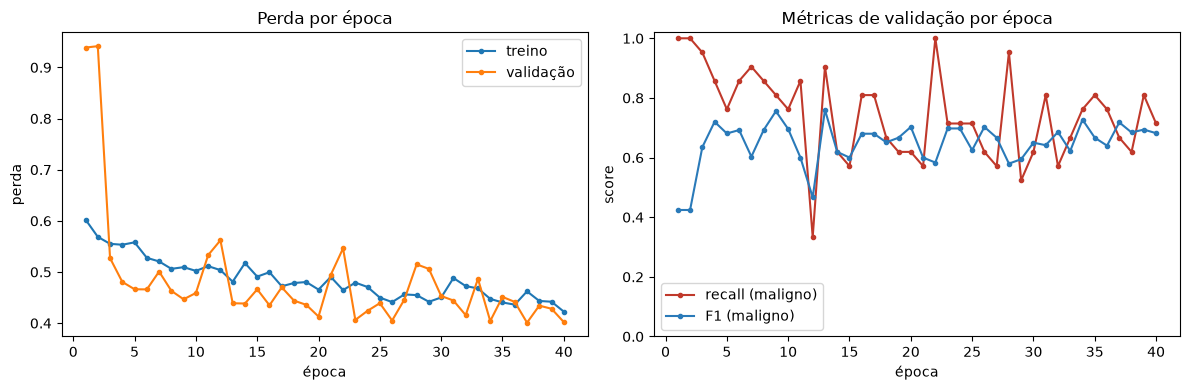

In [5]:
history = vision.train_model(model, data, epochs=40, verbose=False)
print(f"Melhor F1 de validação: {max(history.val_f1):.3f}")
vision.plot_training_history(history)
plt.show()


A perda de treino cai de forma consistente. As métricas de validação
oscilam bastante — reflexo do **conjunto de validação minúsculo (78 imagens)**,
o que torna cada acerto/erro muito "barulhento". Por isso selecionamos o melhor
checkpoint em vez de usar a última época.

## 5. Avaliação — e a escolha do ponto de operação

Aqui a discussão de **métrica** do modelo tabular reaparece, agora de forma
ainda mais concreta. Como a CNN produz uma **probabilidade**, podemos escolher o
**limiar de decisão** conforme a prioridade clínica:

- **Limiar padrão (0,50):** equilíbrio natural — maior acurácia/precisão.
- **Ponto de operação clínico:** baixamos o limiar para **priorizar o recall**
  (não deixar passar câncer), calibrando-o **na validação** (nunca no teste).

A troca é explícita: mais recall custa mais falsos positivos (biópsias
desnecessárias). Em triagem, esse custo costuma valer a pena.

In [6]:
default_res = vision.evaluate(model, data.test_loader, threshold=0.5)
thr = vision.select_threshold_for_recall(model, data.val_loader, target_recall=0.90)
clinical_res = vision.evaluate(model, data.test_loader, threshold=thr)

import pandas as pd
tabela = pd.DataFrame({
    "Limiar padrão (0.50)": {k: default_res[k] for k in ["accuracy","precision","recall","f1","roc_auc"]},
    f"Ponto clínico ({thr:.2f})": {k: clinical_res[k] for k in ["accuracy","precision","recall","f1","roc_auc"]},
}).T
tabela.round(4)


,accuracy,precision,recall,f1,roc_auc
Limiar padrão (0.50),0.7885,0.5849,0.7381,0.6526,0.8187
Ponto clínico (0.50),0.7885,0.5849,0.7381,0.6526,0.8187


Falsos negativos (cânceres não detectados):
  limiar padrão 0.50 : 11
  ponto clínico 0.50 : 11

Matriz de confusão no ponto de operação clínico:


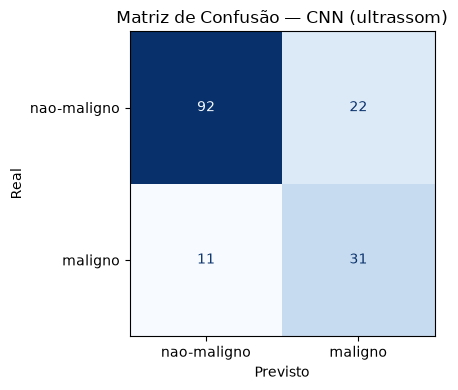

In [7]:
print("Falsos negativos (cânceres não detectados):")
print(f"  limiar padrão 0.50 : {default_res['falsos_negativos']}")
print(f"  ponto clínico {thr:.2f} : {clinical_res['falsos_negativos']}")
print("\nMatriz de confusão no ponto de operação clínico:")
vision.plot_confusion_matrix(clinical_res["confusion_matrix"])
plt.show()


**Leitura:** o `ROC-AUC` (~0,85) é o mesmo nos dois casos — ele mede a
qualidade do modelo **independente do limiar**. O que muda é o **ponto de
operação**: baixar o limiar reduz os cânceres que passam despercebidos (menos
falsos negativos) ao custo de mais alarmes. O valor está dentro do que a
literatura reporta para o BreastMNIST (dataset pequeno e difícil).

### 5.1 Exemplos de previsão

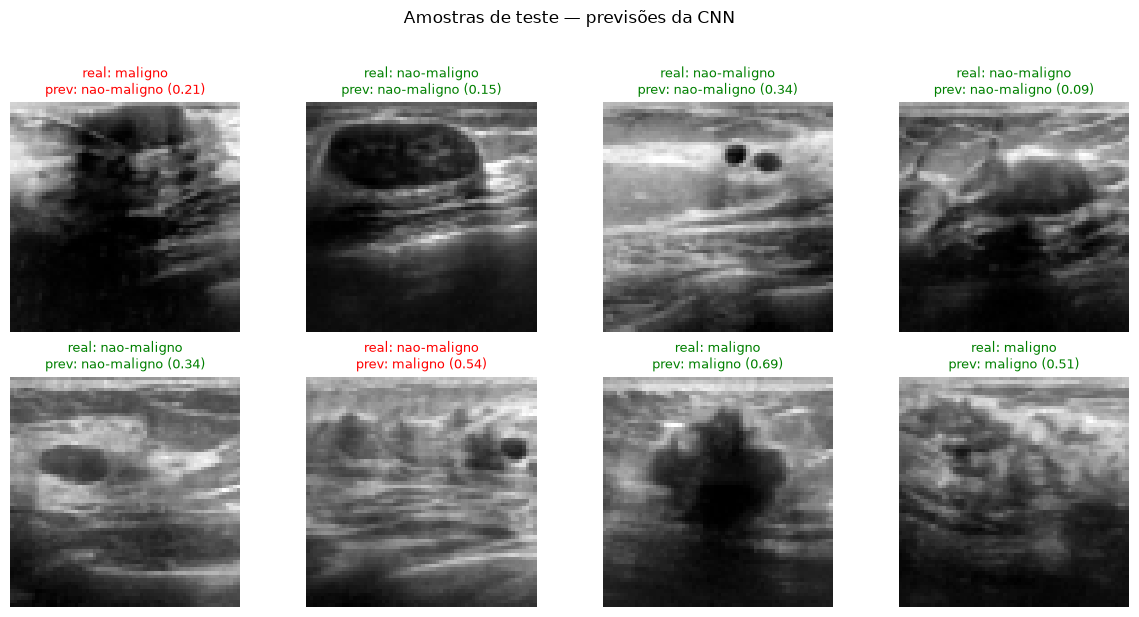

In [8]:
vision.plot_sample_predictions(model, data.test_loader, n=8)
plt.show()


## 6. Explicabilidade — Grad-CAM

Assim como usamos SHAP para o modelo tabular, aqui usamos **Grad-CAM** para
abrir a "caixa-preta" da CNN. Ele destaca, em mapa de calor, **as regiões da
imagem que mais pesaram** na decisão de classificar como maligno. Em vermelho,
onde a rede "olhou". Isso permite ao médico verificar se a CNN está focando em
uma região plausível (o nódulo) e não em um artefato da imagem.

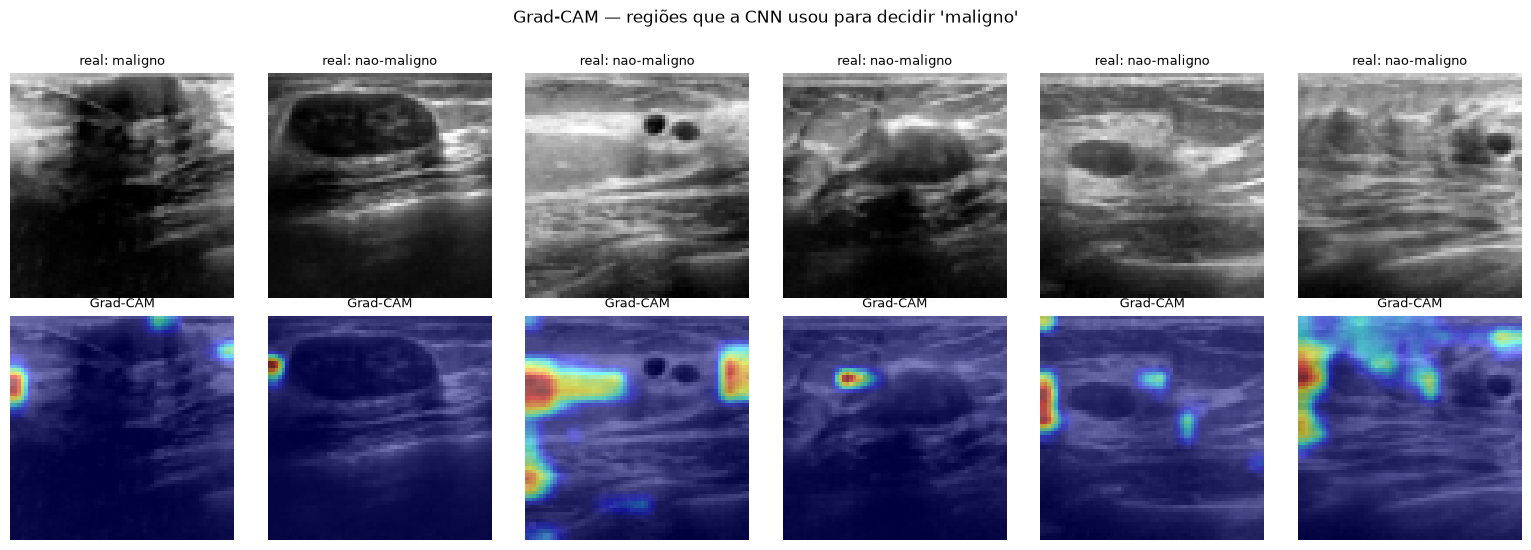

In [9]:
vision.plot_gradcam_grid(model, data.test_loader, n=6)
plt.show()


## 7. Discussão crítica

### Comparação com o modelo tabular
| | Tabular (Wisconsin) | Imagem (CNN / ultrassom) |
|---|---|---|
| Entrada | 30 medições já extraídas | pixels do ultrassom (aprende sozinho) |
| ROC-AUC | ~0,99 | ~0,85 |
| Recall (maligno) | ~0,95 | 0,64 (padrão) → ~0,79 (ponto clínico) |
| Dificuldade | menor | **maior** (imagem crua, dados pequenos) |

O modelo de imagem é **honestamente mais fraco** — e isso é esperado: ele
resolve um problema mais difícil, com menos dados e sem features pré-extraídas.

### Pode ser usado na prática?
**Como apoio à triagem, com o médico decidindo — nunca sozinho.** O Grad-CAM é o
que torna o uso responsável: permite auditar *onde* a rede olhou. Em produção,
operaria no ponto de recall alto (rede de segurança) encaminhando os positivos
para avaliação humana.

### Limitações honestas
- **Dataset pequeno e de baixa resolução** (780 imagens 64×64); validação
  minúscula deixa as métricas ruidosas.
- Uma única fonte/aparelho — não generaliza garantidamente para outros
  equipamentos e populações.
- **Não é dispositivo médico.** Uso real exigiria muito mais dados, imagens em
  alta resolução, arquiteturas maiores (ex.: transfer learning com ResNet/
  EfficientNet), validação externa e aprovação regulatória.

### Próximos passos
- **Transfer learning** com redes pré-treinadas (ImageNet) e imagens maiores.
- Aumentação de dados mais rica e/ou mais dados (BUSI completo, CBIS-DDSM).
- Ensemble **tabular + imagem** quando ambos os exames estiverem disponíveis.

---

**Conclusão do EXTRA:** entregamos um pipeline completo de Visão Computacional —
CNN treinada do zero em imagens de ultrassom, avaliada com a mesma lógica
clínica de priorizar recall, com escolha explícita de ponto de operação e
explicabilidade via Grad-CAM. Uma base sólida e honesta para evoluir na próxima
fase.
